In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import torch

print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("PyTorch:", torch.__version__)
print("TrustFact environment ready!")

Pandas: 2.2.3
NumPy: 2.4.6
Scikit-learn: 1.6.1
PyTorch: 2.14.1+cpu
TrustFact environment ready!


In [ ]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("CPU only")

CUDA available: True
GPU: Tesla T4


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

DATA_DIR = Path("/content/drive/MyDrive/TrustFact/data/raw/liar")

for name in ["train.tsv", "valid.tsv", "test.tsv"]:
    file = DATA_DIR / name
    print(f"{name}: {'FOUND' if file.exists() else 'MISSING'}")

train.tsv: FOUND
valid.tsv: FOUND
test.tsv: FOUND


In [ ]:
import pandas as pd

columns = [
    "id", "label", "statement", "subject", "speaker",
    "speaker_job", "state", "party",
    "barely_true_count", "false_count",
    "half_true_count", "mostly_true_count",
    "pants_on_fire_count", "context"
]

train_df = pd.read_csv(
    DATA_DIR / "train.tsv",
    sep="\t",
    header=None,
    names=columns
)

valid_df = pd.read_csv(
    DATA_DIR / "valid.tsv",
    sep="\t",
    header=None,
    names=columns
)

test_df = pd.read_csv(
    DATA_DIR / "test.tsv",
    sep="\t",
    header=None,
    names=columns
)

print("Training:", train_df.shape)
print("Validation:", valid_df.shape)
print("Testing:", test_df.shape)

display(train_df.head())

Training: (10240, 14)
Validation: (1284, 14)
Testing: (1267, 14)


,id,label,statement,subject,speaker,speaker_job,state,party,barely_true_count,false_count,half_true_count,mostly_true_count,pants_on_fire_count,context
0,2635.json,false,Says the Annies List political group supports ...,abortion,dwayne-bohac,State representative,Texas,republican,0.0,1.0,0.0,0.0,0.0,a mailer
1,10540.json,half-true,When did the decline of coal start? It started...,"energy,history,job-accomplishments",scott-surovell,State delegate,Virginia,democrat,0.0,0.0,1.0,1.0,0.0,a floor speech.
2,324.json,mostly-true,"Hillary Clinton agrees with John McCain ""by vo...",foreign-policy,barack-obama,President,Illinois,democrat,70.0,71.0,160.0,163.0,9.0,Denver
3,1123.json,false,Health care reform legislation is likely to ma...,health-care,blog-posting,NaN,NaN,none,7.0,19.0,3.0,5.0,44.0,a news release
4,9028.json,half-true,The economic turnaround started at the end of ...,"economy,jobs",charlie-crist,NaN,Florida,democrat,15.0,9.0,20.0,19.0,2.0,an interview on CNN


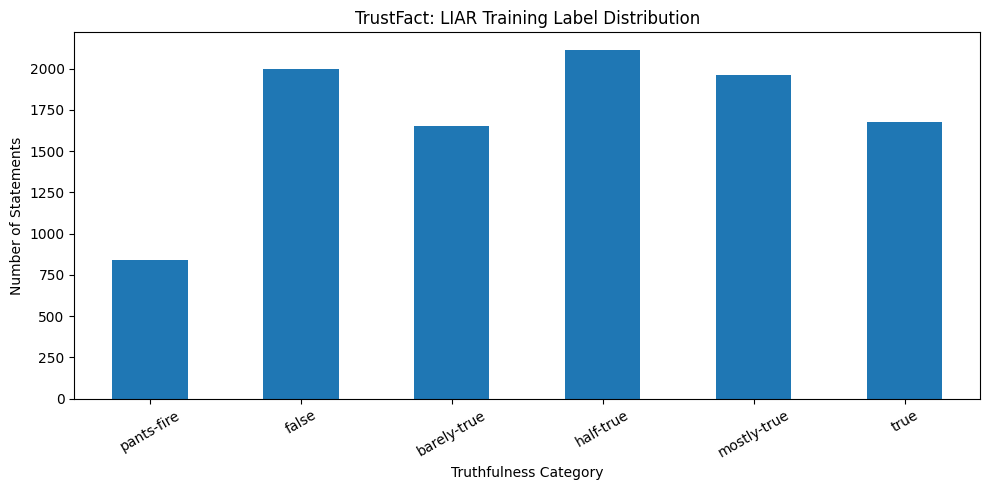

In [ ]:
import matplotlib.pyplot as plt

label_order = [
    "pants-fire", "false", "barely-true",
    "half-true", "mostly-true", "true"
]

counts = train_df["label"].value_counts().reindex(
    label_order, fill_value=0
)

plt.figure(figsize=(10, 5))
counts.plot(kind="bar")

plt.title("TrustFact: LIAR Training Label Distribution")
plt.xlabel("Truthfulness Category")
plt.ylabel("Number of Statements")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
# Check missing values
print("Missing values in training dataset:")
print(train_df.isnull().sum())

# Check duplicate statements
print("\nDuplicate statements:")
print(train_df["statement"].duplicated().sum())

# Check class distribution
print("\nClass distribution:")
print(train_df["label"].value_counts())

Missing values in training dataset:
id                        0
label                     0
statement                 0
subject                   2
speaker                   2
speaker_job            2898
state                  2210
party                     2
barely_true_count         2
false_count               2
half_true_count           2
mostly_true_count         2
pants_on_fire_count       2
context                 102
dtype: int64

Duplicate statements:
17

Class distribution:
label
half-true      2114
false          1995
mostly-true    1962
true           1676
barely-true    1654
pants-fire      839
Name: count, dtype: int64


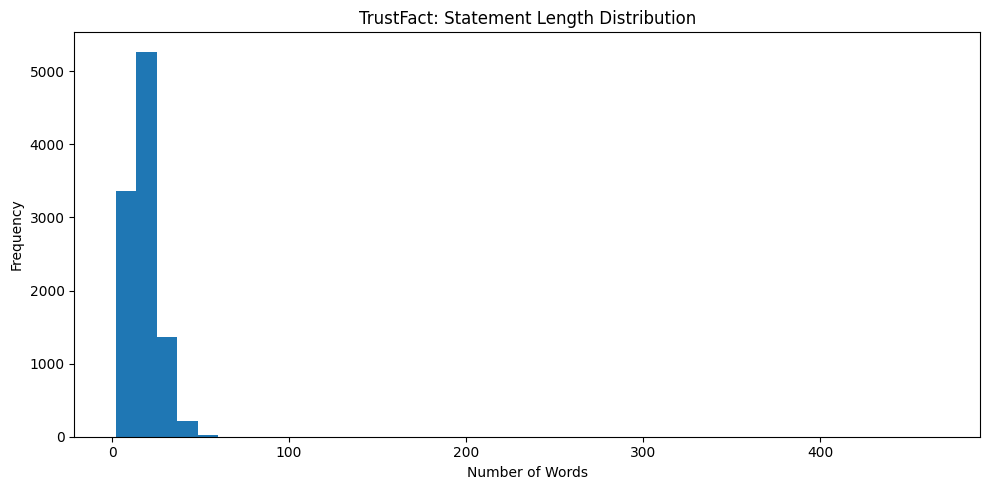

count    10240.000000
mean        18.010059
std          9.658572
min          2.000000
25%         12.000000
50%         17.000000
75%         22.000000
max        467.000000
Name: word_count, dtype: float64


In [ ]:
train_df["word_count"] = (
    train_df["statement"].fillna("").str.split().str.len()
)

plt.figure(figsize=(10, 5))

plt.hist(train_df["word_count"], bins=40)

plt.title("TrustFact: Statement Length Distribution")
plt.xlabel("Number of Words")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

print(train_df["word_count"].describe())

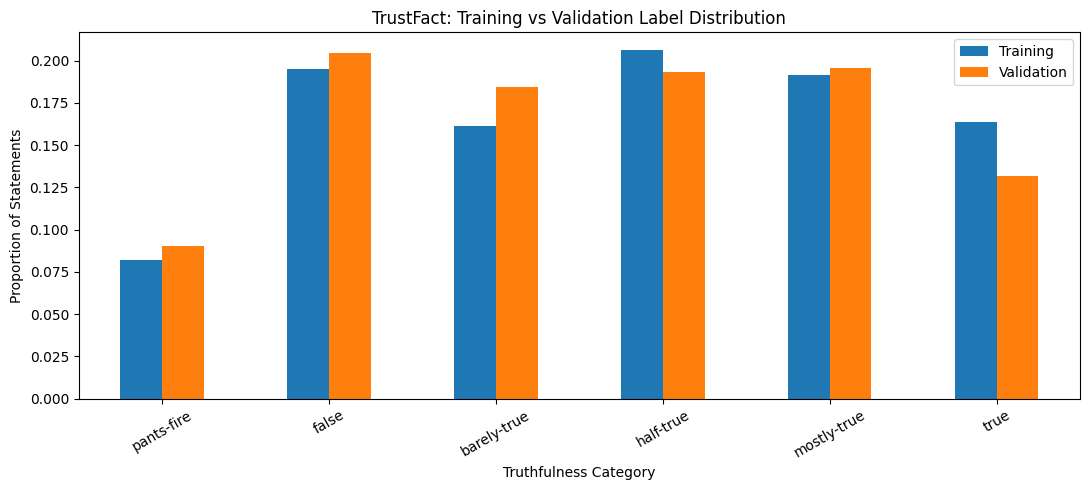

In [ ]:
train_dist = train_df["label"].value_counts(normalize=True)
valid_dist = valid_df["label"].value_counts(normalize=True)

comparison = pd.DataFrame({
    "Training": train_dist,
    "Validation": valid_dist
}).fillna(0)

comparison = comparison.reindex(label_order)

comparison.plot(kind="bar", figsize=(11, 5))

plt.title("TrustFact: Training vs Validation Label Distribution")
plt.xlabel("Truthfulness Category")
plt.ylabel("Proportion of Statements")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [ ]:
from pathlib import Path

OUTPUT_DIR = Path("/content/drive/MyDrive/TrustFact/results/week4")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Save class counts
train_df["label"].value_counts().to_csv(
    OUTPUT_DIR / "train_label_counts.csv"
)

# Save statement-length statistics
train_df["word_count"].describe().to_csv(
    OUTPUT_DIR / "statement_length_statistics.csv"
)

# Save train/validation comparison
comparison.to_csv(
    OUTPUT_DIR / "train_validation_distribution.csv"
)

print("Week 4 EDA results saved successfully.")

Week 4 EDA results saved successfully.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd
import joblib
import time

# Check for missing statements
print("Missing training statements:", train_df["statement"].isna().sum())
print("Missing validation statements:", valid_df["statement"].isna().sum())

# Prepare input text
X_train = train_df["statement"].fillna("").astype(str)
X_valid = valid_df["statement"].fillna("").astype(str)

# Prepare labels
y_train = train_df["label"]
y_valid = valid_df["label"]

print("Training samples:", len(X_train))
print("Validation samples:", len(X_valid))

Missing training statements: 0
Missing validation statements: 0
Training samples: 10240
Validation samples: 1284


In [ ]:
from sklearn.pipeline import Pipeline

lr_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        C=1.0,
        max_iter=2000,
        random_state=42
    ))
])

start = time.time()

lr_pipeline.fit(X_train, y_train)
lr_predictions = lr_pipeline.predict(X_valid)

lr_accuracy = accuracy_score(y_valid, lr_predictions)
lr_f1 = f1_score(y_valid, lr_predictions, average="macro")

print("Logistic Regression Accuracy:", round(lr_accuracy, 4))
print("Logistic Regression Macro-F1:", round(lr_f1, 4))
print("Training time:", round(time.time() - start, 2), "seconds")

Logistic Regression Accuracy: 0.2531
Logistic Regression Macro-F1: 0.2324
Training time: 10.1 seconds


In [ ]:
svm_pipeline = Pipeline([
    ("tfidf", TfidfVectorizer(
        max_features=20000,
        ngram_range=(1, 2),
        sublinear_tf=True
    )),
    ("classifier", LinearSVC(
        C=1.0,
        random_state=42
    ))
])

start = time.time()

svm_pipeline.fit(X_train, y_train)
svm_predictions = svm_pipeline.predict(X_valid)

svm_accuracy = accuracy_score(y_valid, svm_predictions)
svm_f1 = f1_score(y_valid, svm_predictions, average="macro")

print("Linear SVM Accuracy:", round(svm_accuracy, 4))
print("Linear SVM Macro-F1:", round(svm_f1, 4))
print("Training time:", round(time.time() - start, 2), "seconds")

Linear SVM Accuracy: 0.2625
Linear SVM Macro-F1: 0.2582
Training time: 0.82 seconds


In [ ]:
results = pd.DataFrame([
    {
        "Model": "Logistic Regression",
        "Accuracy": lr_accuracy,
        "Macro-F1": lr_f1
    },
    {
        "Model": "Linear SVM",
        "Accuracy": svm_accuracy,
        "Macro-F1": svm_f1
    }
])

display(results)

results.to_csv(
    OUTPUT_DIR / "baseline_model_comparison.csv",
    index=False
)

joblib.dump(
    lr_pipeline,
    OUTPUT_DIR / "logistic_regression_pipeline.joblib"
)

joblib.dump(
    svm_pipeline,
    OUTPUT_DIR / "linear_svm_pipeline.joblib"
)

print("Model comparison and pipelines saved.")

,Model,Accuracy,Macro-F1
0,Logistic Regression,0.253115,0.232384
1,Linear SVM,0.262461,0.258223


Model comparison and pipelines saved.


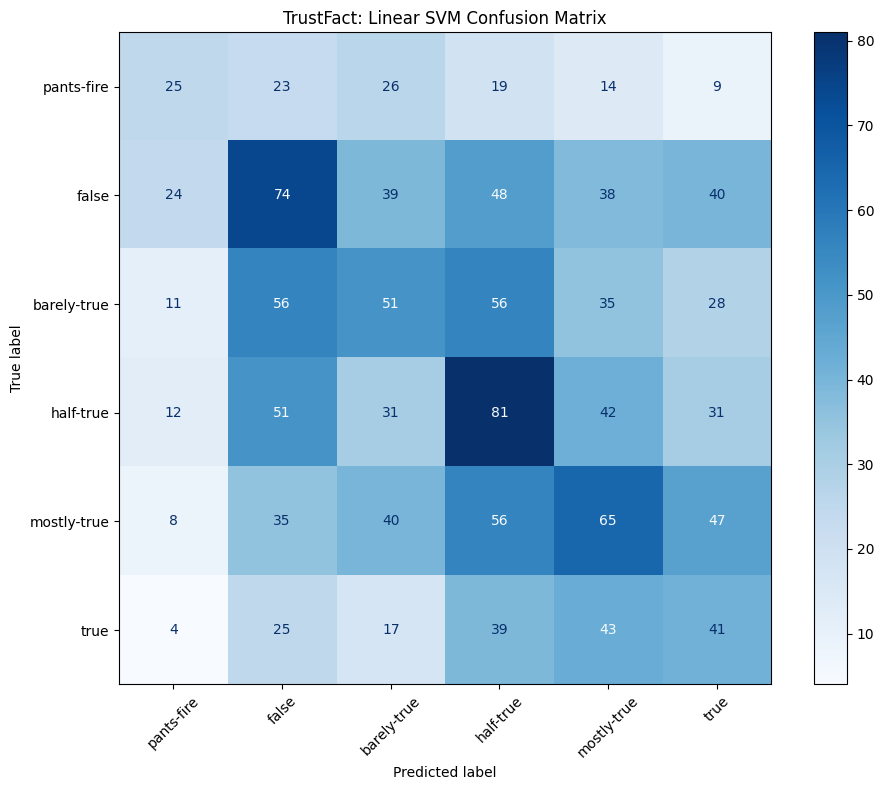

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = [
    "pants-fire", "false", "barely-true",
    "half-true", "mostly-true", "true"
]

fig, ax = plt.subplots(figsize=(10, 8))

ConfusionMatrixDisplay.from_predictions(
    y_valid,
    svm_predictions,
    labels=labels,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

plt.title("TrustFact: Linear SVM Confusion Matrix")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "svm_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
from sklearn.metrics import classification_report

print("LINEAR SVM CLASSIFICATION REPORT")

print(
    classification_report(
        y_valid,
        svm_predictions,
        labels=labels,
        zero_division=0
    )
)

print("\nLOGISTIC REGRESSION CLASSIFICATION REPORT")

print(
    classification_report(
        y_valid,
        lr_predictions,
        labels=labels,
        zero_division=0
    )
)

LINEAR SVM CLASSIFICATION REPORT
              precision    recall  f1-score   support

  pants-fire       0.30      0.22      0.25       116
       false       0.28      0.28      0.28       263
 barely-true       0.25      0.22      0.23       237
   half-true       0.27      0.33      0.30       248
 mostly-true       0.27      0.26      0.27       251
        true       0.21      0.24      0.22       169

    accuracy                           0.26      1284
   macro avg       0.26      0.26      0.26      1284
weighted avg       0.26      0.26      0.26      1284


LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

  pants-fire       0.41      0.08      0.13       116
       false       0.26      0.32      0.29       263
 barely-true       0.23      0.16      0.19       237
   half-true       0.24      0.35      0.29       248
 mostly-true       0.28      0.28      0.28       251
        true       0.21      0.22      0.22       169

 

In [ ]:
from sklearn.metrics import classification_report
import pandas as pd

svm_report = pd.DataFrame(
    classification_report(
        y_valid,
        svm_predictions,
        labels=labels,
        output_dict=True,
        zero_division=0
    )
).transpose()

lr_report = pd.DataFrame(
    classification_report(
        y_valid,
        lr_predictions,
        labels=labels,
        output_dict=True,
        zero_division=0
    )
).transpose()

svm_report.to_csv(
    OUTPUT_DIR / "svm_classification_report.csv"
)

lr_report.to_csv(
    OUTPUT_DIR / "lr_classification_report.csv"
)

print("Detailed evaluation reports saved.")

Detailed evaluation reports saved.


In [ ]:
error_analysis = valid_df.copy()

error_analysis["predicted_label"] = svm_predictions

error_analysis["correct"] = (
    error_analysis["label"] ==
    error_analysis["predicted_label"]
)

errors = error_analysis[
    ~error_analysis["correct"]
]

print("Total incorrect predictions:", len(errors))

display(
    errors[
        ["statement", "label", "predicted_label"]
    ].head(20)
)

errors.to_csv(
    OUTPUT_DIR / "svm_prediction_errors.csv",
    index=False
)

Total incorrect predictions: 947


,statement,label,predicted_label
0,We have less Americans working now than in the...,barely-true,mostly-true
3,Says nearly half of Oregons children are poor.,half-true,true
5,Says when armed civilians stop mass shootings ...,false,half-true
6,Says Tennessee is providing millions of dollar...,true,half-true
7,The health care reform plan would set limits s...,false,mostly-true
8,Says Donald Trump started his career back in 1...,true,half-true
9,Bill White has a long history of trying to lim...,half-true,pants-fire
10,John McCains chief economic adviser during the...,half-true,barely-true
11,"Says 21,000 Wisconsin residents got jobs in 20...",false,half-true
12,State revenue projections have missed the mark...,half-true,barely-true


In [ ]:
import pandas as pd

# Count actual versus predicted labels for incorrect cases
error_pairs = (
    errors.groupby(["label", "predicted_label"])
    .size()
    .reset_index(name="error_count")
    .sort_values("error_count", ascending=False)
)

print("Top 15 most common classification errors:")
display(error_pairs.head(15))

error_pairs.to_csv(
    OUTPUT_DIR / "svm_error_patterns.csv",
    index=False
)

Top 15 most common classification errors:


,label,predicted_label,error_count
0,barely-true,false,56
1,barely-true,half-true,56
17,mostly-true,half-true,56
11,half-true,false,51
6,false,half-true,48
19,mostly-true,true,47
28,true,mostly-true,43
12,half-true,mostly-true,42
15,mostly-true,barely-true,40
9,false,true,40


In [ ]:
label_severity = {
    "pants-fire": 0,
    "false": 1,
    "barely-true": 2,
    "half-true": 3,
    "mostly-true": 4,
    "true": 5
}

analysis = valid_df[["statement", "label"]].copy()
analysis["prediction"] = svm_predictions

analysis["actual_score"] = analysis["label"].map(label_severity)
analysis["predicted_score"] = analysis["prediction"].map(label_severity)

analysis["error_distance"] = abs(
    analysis["actual_score"] - analysis["predicted_score"]
)

print("Mean absolute label distance:")
print(round(analysis["error_distance"].mean(), 4))

print("\nError distance distribution:")
display(
    analysis["error_distance"]
    .value_counts()
    .sort_index()
)

analysis.to_csv(
    OUTPUT_DIR / "svm_error_severity.csv",
    index=False
)

Mean absolute label distance:
1.4322

Error distance distribution:


,count
error_distance,
0,337
1,417
2,281
3,149
4,87
5,13


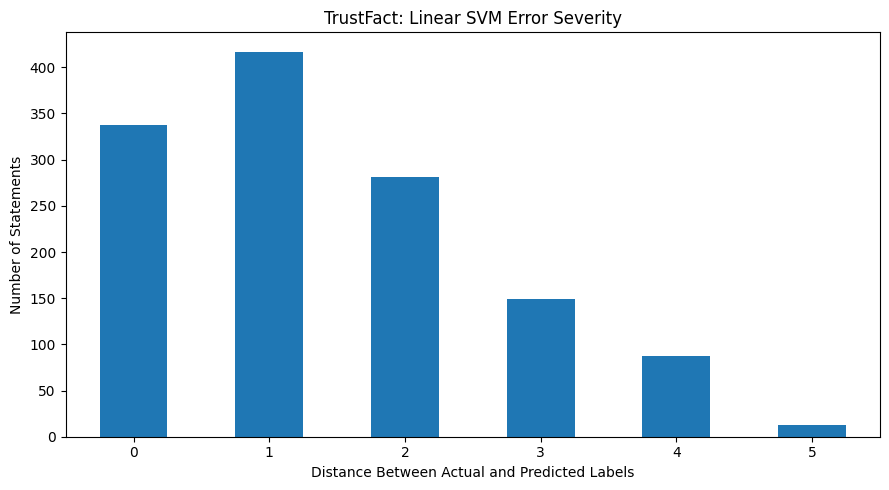

In [ ]:
import matplotlib.pyplot as plt

severity_counts = (
    analysis["error_distance"]
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(9, 5))

severity_counts.plot(kind="bar")

plt.title("TrustFact: Linear SVM Error Severity")
plt.xlabel("Distance Between Actual and Predicted Labels")
plt.ylabel("Number of Statements")
plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "svm_error_severity.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [3]:
from pathlib import Path

OUTPUT_DIR = Path("/content/drive/MyDrive/TrustFact/results/week4")

for file in sorted(OUTPUT_DIR.iterdir()):
    print(file.name)

baseline_model_comparison.csv
linear_svm_pipeline.joblib
logistic_regression_pipeline.joblib
lr_classification_report.csv
statement_length_statistics.csv
svm_classification_report.csv
svm_confusion_matrix.png
svm_error_patterns.csv
svm_error_severity.csv
svm_error_severity.png
svm_prediction_errors.csv
train_label_counts.csv
train_validation_distribution.csv
